# Modèle de sentiment (avis en portugais)
Baseline TF-IDF + régression logistique vs réseau de neurones PyTorch, courbes d'apprentissage et analyse d'erreurs.

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report
from shoppulse.models import sentiment

In [2]:
df = sentiment.load_reviews()
print(len(df), 'avis | part positive =', round(df['label'].mean(), 3))
tr, te = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)

40950 avis | part positive = 0.647


## Baseline TF-IDF + régression logistique

In [3]:
base = sentiment.build_baseline(); base.fit(tr['texte'], tr['label'])
pred = base.predict(te['texte'])
print('F1 baseline =', round(f1_score(te['label'], pred), 4))
print(classification_report(te['label'], pred))

F1 baseline = 0.9148
              precision    recall  f1-score   support

           0       0.82      0.89      0.85      2889
           1       0.94      0.89      0.91      5301

    accuracy                           0.89      8190
   macro avg       0.88      0.89      0.88      8190
weighted avg       0.90      0.89      0.89      8190



## Réseau de neurones PyTorch — courbes d'apprentissage

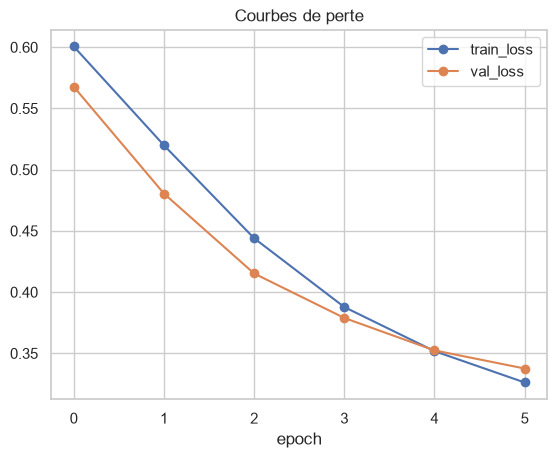

F1 réseau de neurones = 0.8988


In [4]:
vocab = sentiment.build_vocab(tr['texte'].tolist())
model, hist = sentiment.train_nn(tr['texte'].tolist(), tr['label'].tolist(), vocab)
h = pd.DataFrame(hist); h.plot(marker='o'); plt.title('Courbes de perte'); plt.xlabel('epoch'); plt.show()
npred = sentiment.nn_predict(model, te['texte'].tolist(), vocab)
print('F1 réseau de neurones =', round(f1_score(te['label'], npred), 4))

## Analyse d'erreurs

In [5]:
err = te.loc[pred != te['label'], ['texte','review_score','label']].head(8)
err

,texte,review_score,label
7909,Já comprei muitos produtos das Lojas lannister...,5,1
33287,Comprei 2 produtos no pedido 03-49282XXXX! Par...,4,1
38824,Pinhão não serve na fazer 2008,5,1
23802,"Excelente produto, correto, bem embalado mas c...",3,0
16343,Muito rápido na entrega,3,0
27222,mais uma ves parabens a lojas americana ea tar...,3,0
33605,"Como foram dois produtos, ainda estou no aguar...",5,1
7981,"Rapidez na entrega , lucro rápido",3,0


## Conclusion
La baseline TF-IDF est très compétitive (F1 ≈ 0,91) et plus légère à servir. Le réseau de neurones apprend correctement (perte décroissante) sans surpasser la baseline ici. Les erreurs concernent surtout les avis ironiques ou mixtes (note incohérente avec le texte). L'API sert la baseline (robuste et compacte).